# 04 · Ensembles, Kenya → Ghana transfer, and the fairness audit

**Owner:** Eugene (P4). **Issues:** #54 (this notebook), #18 (RF, LightGBM), #23 and #24 (Part C), #26 and #50 (Part D), #28 (Findex).

This notebook audits the model that actually ships: **logistic regression, Platt-calibrated**, decision threshold from `configs/cost_matrix.yaml` (`artifacts/task2_clf.joblib`, built by `make artifacts`). Everything here runs on the shared pipeline in `src/`. The only logic defined in this notebook is the cost of the mitigation options in section 3.4.

**What changed from the PR #46 draft.** The draft had four known problems, and all four are fixed:
1. Every threshold is now applied to **calibrated** probabilities (`calibrate_oof`, Platt, as deployed).
2. The mitigation now shows its **cost in money**, next to how many more people it approves (§3.4).
3. A **proxy analysis** has been added (§3.3).
4. The Model Card, Datasheet, regulatory map and decline message are written up in `docs/audit/`.

Run `make features artifacts` first. The first section trains 3 models × 2 schemes, which takes about a minute.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.analysis.data_profile import findex_access
from src.evaluation import (
    add_loan_size_band,
    calibrate_oof,
    classification_metrics,
    cost_matrix_threshold,
    decision_cost_by_group,
    disaggregated_evaluation,
    proxy_strength,
    run_domain_classifier,
)
from src.processing import load_features
from src.serving.batch import score_frame
from src.training import run_cv
from src.visualization import (
    plot_domain_scores,
    plot_feature_shift,
    plot_group_selection_rates,
    plot_reliability,
    plot_shift_drivers,
)

pd.set_option("display.width", 160)
df = load_features()
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

cost = cost_matrix_threshold()       # shipped: KES, configs/cost_matrix.yaml (D-19)
THR = cost["threshold"]
THR_GHS = 0.036                      # Henry's cedi cost matrix from Ghana's own loans (D-22), as a sensitivity
print(f"Shipped threshold {THR:.4f}  (C_FP {cost['c_fp']:.0f} KES, C_FN {cost['c_fn']:.0f} KES);  cedi threshold {THR_GHS}")

Shipped threshold 0.0194  (C_FP 88 KES, C_FN 4449 KES);  cedi threshold 0.036


## 1. Random Forest and LightGBM against the shipped logistic regression (#18)

All three models use the same features (D-18: no macro columns, and a single amount column in USD). Each is scored twice: by customer (`fold_group`, the split we use to compare models, D-7) and by time (`temporal`, the honest forecast).

In [2]:
models = ["logreg", "random_forest", "lightgbm"]
oof, rows = {}, []
for m in models:
    for scheme in ["fold_group", "temporal"]:
        p = run_cv(df, model_name=m, task="task2", scheme=scheme, save_preds=False)
        r = classification_metrics(p["y_true"], p["y_pred"], threshold=THR)
        rows.append({"model": m, "scheme": scheme, "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"]})
        if scheme == "fold_group":
            oof[m] = p.assign(y_cal=calibrate_oof(p["y_true"], p["y_pred"], p["fold"], method="platt"))
ranking = pd.DataFrame(rows).pivot(index="model", columns="scheme", values=["roc_auc", "pr_auc"]).round(3)
ranking

roc_auc              pr_auc         
scheme        fold_group temporal fold_group temporal
model                                                
lightgbm           0.849    0.582      0.195    0.148
logreg             0.843    0.633      0.176    0.134
random_forest      0.871    0.618      0.203    0.156

**Reading.** By customer, Random Forest ranks defaulters best (PR-AUC 0.203), LightGBM comes second (0.195) and logistic regression third (0.176). The base rate is 0.018, so all three are roughly ten times better than guessing. By time, every model falls to a ROC-AUC of about 0.6, and the order changes. The ensembles' advantage is small, and it does not hold up for future loans. That is why shipping the logistic regression costs little in accuracy, and the credit committee gets a model it can explain coefficient by coefficient.

**How the two ensembles differ.** Random Forest uses *bagging*. It averages many deep trees, each grown on a bootstrap sample with a random subset of features, and the averaging lowers variance. LightGBM uses *boosting*. It adds shallow trees one at a time, each fitted to the gradient of the log-loss of the model built so far, and this lowers bias. The derivation is in `docs/derivations/boosting.md`, and the settings are in `configs/models.yaml`.

### 1.1 Calibrate before any threshold (fixes draft problem 1)

Class weights (`balanced`, `scale_pos_weight`) tell the model that defaults matter about 54 times more than repayments. That improves ranking, but it pushes every probability up. The deployment bundle therefore applies Platt scaling, which is fitted out of fold. The table below reads approval rates off raw scores and off calibrated scores.

,model,true_default_rate,mean_raw,mean_calibrated,approved_raw,approved_calibrated,approved_at_0.036,recall,precision
0,logreg,0.018,0.322,0.018,0.042,0.828,0.910,0.672,0.072
1,random_forest,0.018,0.258,0.018,0.017,0.810,0.890,0.757,0.073
2,lightgbm,0.018,0.150,0.018,0.420,0.741,0.858,0.773,0.055


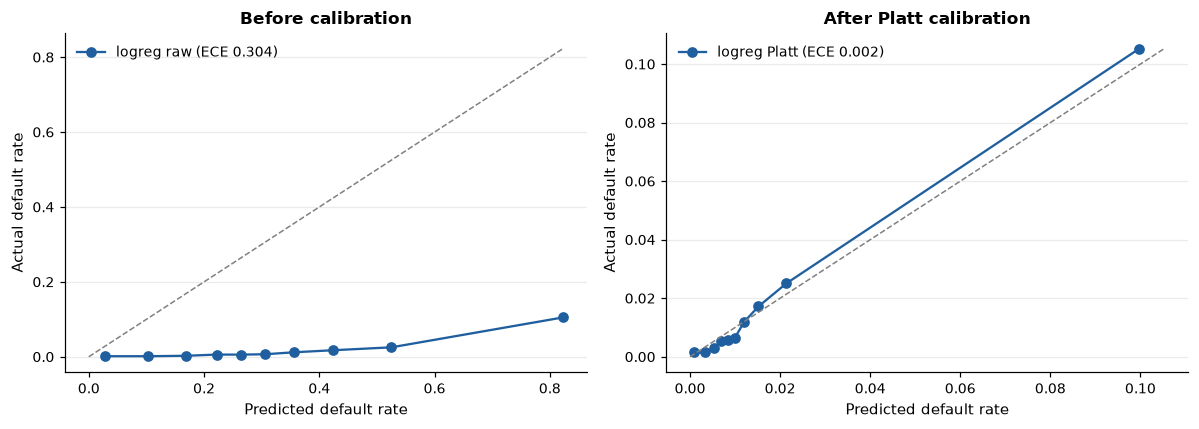

In [3]:
cal_rows = []
for m, p in oof.items():
    r = classification_metrics(p["y_true"], p["y_cal"], threshold=THR)
    cal_rows.append({
        "model": m,
        "true_default_rate": p["y_true"].mean(),
        "mean_raw": p["y_pred"].mean(),
        "mean_calibrated": p["y_cal"].mean(),
        "approved_raw": np.mean(p["y_pred"] <= THR),
        "approved_calibrated": np.mean(p["y_cal"] <= THR),
        f"approved_at_{THR_GHS}": np.mean(p["y_cal"] <= THR_GHS),
        "recall": r["recall"],
        "precision": r["precision"],
    })
display(pd.DataFrame(cal_rows).round(3))

lr = oof["logreg"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_reliability(lr["y_true"], {"logreg raw": lr["y_pred"].to_numpy()}, ax=axes[0])
axes[0].set_title("Before calibration")
plot_reliability(lr["y_true"], {"logreg Platt": lr["y_cal"].to_numpy()}, ax=axes[1])
axes[1].set_title("After Platt calibration")
plt.tight_layout()
plt.show()

**Reading.** The raw logistic scores average 0.32, against a true default rate of 0.018. If you apply the shipped threshold to them, only about 4% of applicants are approved, so the draft's fairness tables, which were read off raw scores, were wrong by an order of magnitude. After calibration the mean prediction equals the base rate, and the model approves 83% of Kenyan applicants, which rises to 91% under the cedi threshold. Calibration does not change the ranking (PR-AUC is unchanged), so from here on every rate, threshold and cost uses calibrated probabilities.

## 2. Part C: does a model trained on Kenya transfer to Ghana? (#23, #24)

### 2.1 How different are Ghana's applications?

rows  median_amount_usd  mean_duration_days  new_borrower_share  median_past_loans  mean_past_labelled  mean_inflation
split country_id                                                                                                                         
test  Ghana        3525            494.399              35.938               0.018                5.0               0.000          12.718
      Kenya       15069             46.188               8.289               0.007                9.0              11.087           6.197
train Kenya       68654             47.411               8.545               0.008                9.0              11.050           6.203

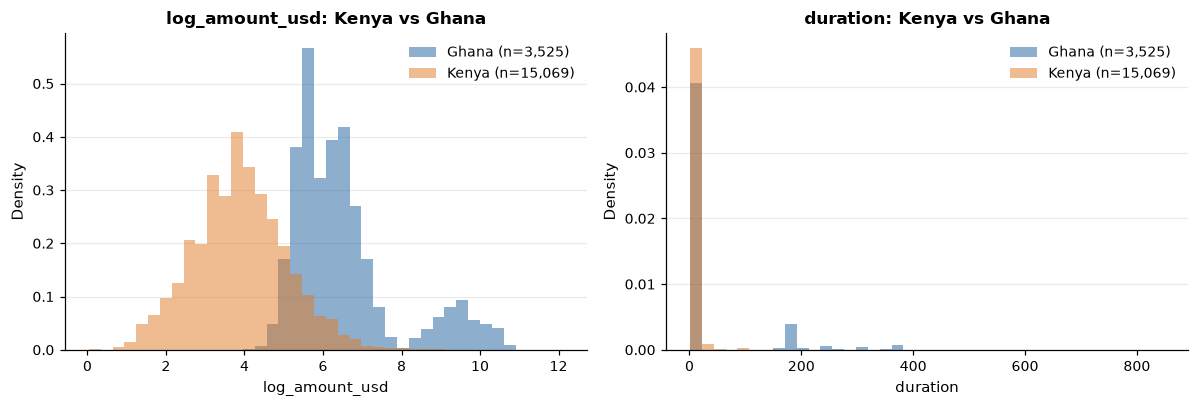

In [4]:
summary = (
    df.assign(amount_usd=np.expm1(df["log_amount_usd"]))
    .groupby(["split", "country_id"])
    .agg(rows=("ID", "count"), median_amount_usd=("amount_usd", "median"), mean_duration_days=("duration", "mean"),
         new_borrower_share=("is_new_borrower", "mean"), median_past_loans=("n_past_loans", "median"),
         mean_past_labelled=("n_past_labelled", "mean"), mean_inflation=("macro_inflation", "mean"))
    .round(3)
)
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_feature_shift(test, "log_amount_usd", ax=axes[0])
plot_feature_shift(test, "duration", ax=axes[1])
plt.tight_layout()
plt.show()

**Reading.** The median Ghanaian loan is about USD 494, roughly ten times the Kenyan median of USD 46–47. Ghanaian loans also run about four times longer (36 days against 8). Two further gaps are not about borrower behaviour:
- **Label history is structurally zero in Ghana.** `n_past_labelled` and the past-default features count earlier loans with a *known outcome*. Labels exist only in `Train.csv`, and Train is all Kenyan, so every Ghanaian row has a labelled history of 0. A Ghanaian with five earlier loans looks, to the model, like someone whose loans have not yet come due. That is a property of the data files, not of the borrowers.
- **The macro gap.** Ghana's previous-year inflation averages 12.7% in these rows, against 6.2% for Kenya, and it reached 31% in 2022. Since D-18 the macro columns are no longer model inputs, so this matters here only for the shift study.

### 2.2 Domain classifier: can a model tell Kenya from Ghana?

If the domain classifier cannot separate the two countries (AUC ≈ 0.5), Kenyan validation results carry over to Ghana. If it can (AUC ≈ 1), Ghana's scores are extrapolation. I run it on five feature sets, so we can see *what* separates the countries. The **effective sample share** (ESS / n) of the importance weights shows whether reweighting Kenyan validation to look like Ghana is workable: near 1 is fine, near 0 means a handful of Kenyan rows would carry the whole estimate.

,features,domain_roc_auc,effective_sample_share,top_drivers
0,model features (D-18),0.9969,0.0221,"n_past_labelled, n_past_loans, log_amount_usd"
1,minus label history,0.9852,0.0418,"log_amount_usd, n_past_loans, n_lenders_on_loan"
2,minus label history and amount,0.9584,0.0749,"n_lenders_on_loan, disb_month, Lender_portion_..."
3,plus lender and loan type,1.0000,0.3398,"loan_type_Type_3, lender_id_267278, lender_id_..."
4,plus macro columns,1.0000,1.0000,"macro_fx, macro_unemployment, macro_deposit_rate"


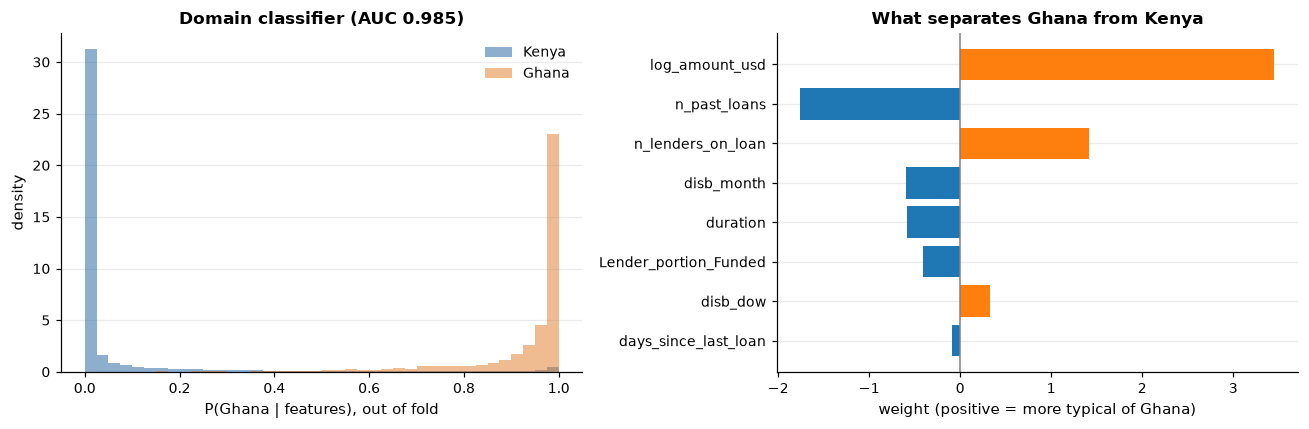

In [5]:
LABEL_HISTORY = ("n_past_labelled", "n_past_defaults", "past_default_rate", "days_since_last_default")
variants = {
    "model features (D-18)": {},
    "minus label history": {"drop_cols": LABEL_HISTORY},
    "minus label history and amount": {"drop_cols": LABEL_HISTORY + ("log_amount_usd",)},
    "plus lender and loan type": {"include_categoricals": True},
    "plus macro columns": {"include_macro": True},
}
dom = {name: run_domain_classifier(df, **kw) for name, kw in variants.items()}
display(pd.DataFrame([
    {"features": name, "domain_roc_auc": d["domain_roc_auc"], "effective_sample_share": d["effective_sample_share"],
     "top_drivers": ", ".join(d["top_shift_drivers"]["feature"].str.split("__").str[-1].head(3))}
    for name, d in dom.items()
]).round(4))

d = dom["minus label history"]
is_gh = df["country_id"].eq("Ghana").to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_domain_scores(d["oof_ghana_prob"], is_gh, d["domain_roc_auc"], ax=axes[0])
plot_shift_drivers(d["top_shift_drivers"], top=8, ax=axes[1])
plt.tight_layout()
plt.show()

**Reading.**
- On the model's own features the classifier separates the countries almost perfectly (AUC 0.997), and the top driver is `n_past_labelled`, the structural zero from §2.1.
- Removing the label-history fields lowers the AUC only to 0.985. The remaining drivers are real differences: loan size, the number of earlier loans, and two-lender loans.
- Removing the amount as well still leaves an AUC of 0.958.
- Adding lender and loan type, or the macro columns, makes the separation total (AUC 1.0).

So Ghana is a different population on every view, not only because of an artefact. **Importance weighting cannot fix this.** With the label history removed, the effective sample share is 0.04, which means the "reweighted Kenyan validation" would rest on about 4% of Kenyan rows, all of them atypical. I tried it as the brief suggests, and I am reporting that it is unusable, rather than quoting a reweighted metric that would look precise but is not.

### 2.3 What the shipped scorer does with Ghanaian applications

This uses the real product (`score_frame`, which applies the same rule as `score_application`): calibrated probability, decline above the threshold, otherwise approve or *limit* to the Task 1 amount.

In [6]:
sc = score_frame(test)
by_country = sc.groupby("country_id").agg(
    applications=("ID", "count"), mean_p=("probability_of_default", "mean"), median_p=("probability_of_default", "median"),
    needs_review=("needs_review", "mean"), declined_at_cedi_threshold=("probability_of_default", lambda s: np.mean(s > THR_GHS)),
)
mix = pd.crosstab(sc["country_id"], sc["decision"], normalize="index")
limited = sc[sc["decision"] == "limit"]
by_country["median_limit_over_request"] = limited.groupby("country_id").apply(lambda g: (g["limit_local"] / g["requested_local"]).median())
display(by_country.join(mix).round(3))

# Sensitivity: Ghana's label history is unknown, not zero. Score it again as if every earlier loan had matured and been repaid.
gh = test[test["country_id"] == "Ghana"]
clean = gh.assign(n_past_labelled=gh["n_past_loans"], past_default_rate=np.where(gh["n_past_loans"] > 0, 0.0, np.nan))
alt = score_frame(clean)
pd.DataFrame({
    "as built (history = 0)": sc.loc[sc["country_id"] == "Ghana", "decision"].value_counts(normalize=True),
    "history assumed clean": alt["decision"].value_counts(normalize=True),
}).fillna(0).round(3)

,applications,mean_p,median_p,needs_review,declined_at_cedi_threshold,median_limit_over_request,approve,decline,limit
country_id,,,,,,,,,
Ghana,3525,0.081,0.011,1.000,0.189,0.159,0.000,0.299,0.701
Kenya,15069,0.017,0.009,0.009,0.085,0.500,0.413,0.170,0.416


,as built (history = 0),history assumed clean
decision,,
decline,0.299,0.787
limit,0.701,0.213


**Reading.**
- **No Ghanaian application is approved in full.** 70% are cut to a limit and 30% are declined, against 41% full approval in Kenya. The limits are a small fraction of what was asked for: the median Ghanaian limit is about 16% of the request (about GHS 430 against GHS 3,000), because the limit model learned Kenyan loan sizes. Ghana's mean default probability is 0.081, against 0.017 in Kenya.
- **Since D-18, the risk is no longer the one the brief warns about.** Before D-18, the scorer gave every Ghanaian a probability near 0 and approved all of them, because the macro columns extrapolated. Now the risk runs the other way: NkwaPay would under-lend and exclude.
- **The Ghana numbers are not stable.** If Ghana's unknown label history is treated as clean instead of zero, the decline share moves from 30% to 79%. A decision rule that swings that far on an assumption about a field we cannot observe is not evidence about Ghanaian borrowers.
- Every Ghanaian application is flagged `needs_review`, and that is the right behaviour today.

### 2.4 What evidence NkwaPay needs before trusting Ghana scores (#24)

The size of the pilot follows from one question: how many labelled loans are needed to measure Ghana's default rate within ±2 percentage points?

In [7]:
p_guess, margin, z = 0.08, 0.02, 1.96          # Ghana's mean predicted risk; ±2 pp at 95%
n_overall = int(np.ceil(z**2 * p_guess * (1 - p_guess) / margin**2))
print(f"Loans needed to estimate the Ghana default rate to ±{margin:.0%}: {n_overall}")
print(f"For 5 calibration bins of that precision: about {5 * n_overall:,} loans")

Loans needed to estimate the Ghana default rate to ±2%: 707
For 5 calibration bins of that precision: about 3,535 loans


**Plan.**
1. **Capped pilot.** About **3,500 Ghanaian loans** (5 bins × ~700), at the smallest product size, with a hard GHS cap and a human approving each decline. Ghanaian loans run 36 days on average, so outcomes mature in about **3 months**.
2. **Fix the inputs first.** Encode label history as *unknown* rather than 0 for borrowers whose earlier loans are not in our labelled data. Map Ghana's lenders and products to Kenyan ones where the terms match. Re-run §2.2: the domain AUC should fall as structural artefacts are removed.
3. **Recalibrate on Ghanaian outcomes.** Fit a Ghana-specific Platt calibrator on the pilot labels. Accept the model only if (a) Ghana PR-AUC is clearly above Ghana's base rate, and (b) the reliability curve is within ±2 pp per bin.
4. **Set the threshold in cedis.** Use Henry's cedi cost matrix (D-22, p\* = 0.036) once the team agrees to switch the config.
5. **Monitoring triggers.** Pause automation and go back to manual review if any of these happens:
   - the domain-classifier AUC on new applications moves by more than 0.05 from the pilot;
   - the monthly default rate leaves the calibrated band;
   - approval of first-time borrowers falls below the agreed floor (§3.4).

## 3. Part D: fairness audit of the shipped model (#26, #50)

All tables use **calibrated, out-of-fold (GroupKFold) logistic regression** predictions on Kenyan Train, at the shipped threshold. Ghana has no labels, so it appears only in the country slice.

### 3.1 Approval and error rates by group

--- tenure


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,repeat,68087,0.835,0.017,0.017,0.127,0.118,0.157,1.0
1,new,567,0.000,0.210,0.185,0.569,0.347,1.000,0.0


--- loan_size_band


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,Q2_medium,17190,0.839,0.016,0.016,0.168,0.129,0.152,0.954
1,Q1_small,17166,0.880,0.013,0.012,0.051,0.086,0.116,1.000
2,Q4_very_large,17164,0.755,0.029,0.028,0.201,0.158,0.230,0.858
3,Q3_large,17134,0.839,0.015,0.018,0.254,0.119,0.152,0.954


--- lender_id


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,267278,64653,0.876,0.012,0.013,0.077,0.088,0.120,1.000
1,251804,3542,0.067,0.089,0.082,0.124,0.168,0.930,0.077
2,267277,271,0.007,0.295,0.270,0.541,0.453,0.995,0.008
3,245684,188,0.069,0.415,0.332,0.717,0.601,0.900,0.079


--- loan_type


,group,n,selection_rate,actual_default_rate,mean_pred_prob,pr_auc,f1,fpr,disparate_impact_ratio
0,Type_1,61723,0.914,0.008,0.010,0.025,0.046,0.085,0.914
1,Type_7,2790,0.016,0.084,0.071,0.137,0.157,0.982,0.016
2,Type_5,1521,0.028,0.080,0.082,0.085,0.148,0.972,0.028
3,Type_4,1235,0.023,0.123,0.127,0.194,0.222,0.975,0.023
4,Type_10,466,0.601,0.026,0.020,0.071,0.061,0.396,0.601
5,Type_6,357,0.006,0.106,0.107,0.096,0.193,0.994,0.006
6,Type_9,205,0.010,0.176,0.166,0.211,0.293,0.994,0.010
7,Type_14,99,0.000,0.717,0.538,0.780,0.835,1.000,0.000


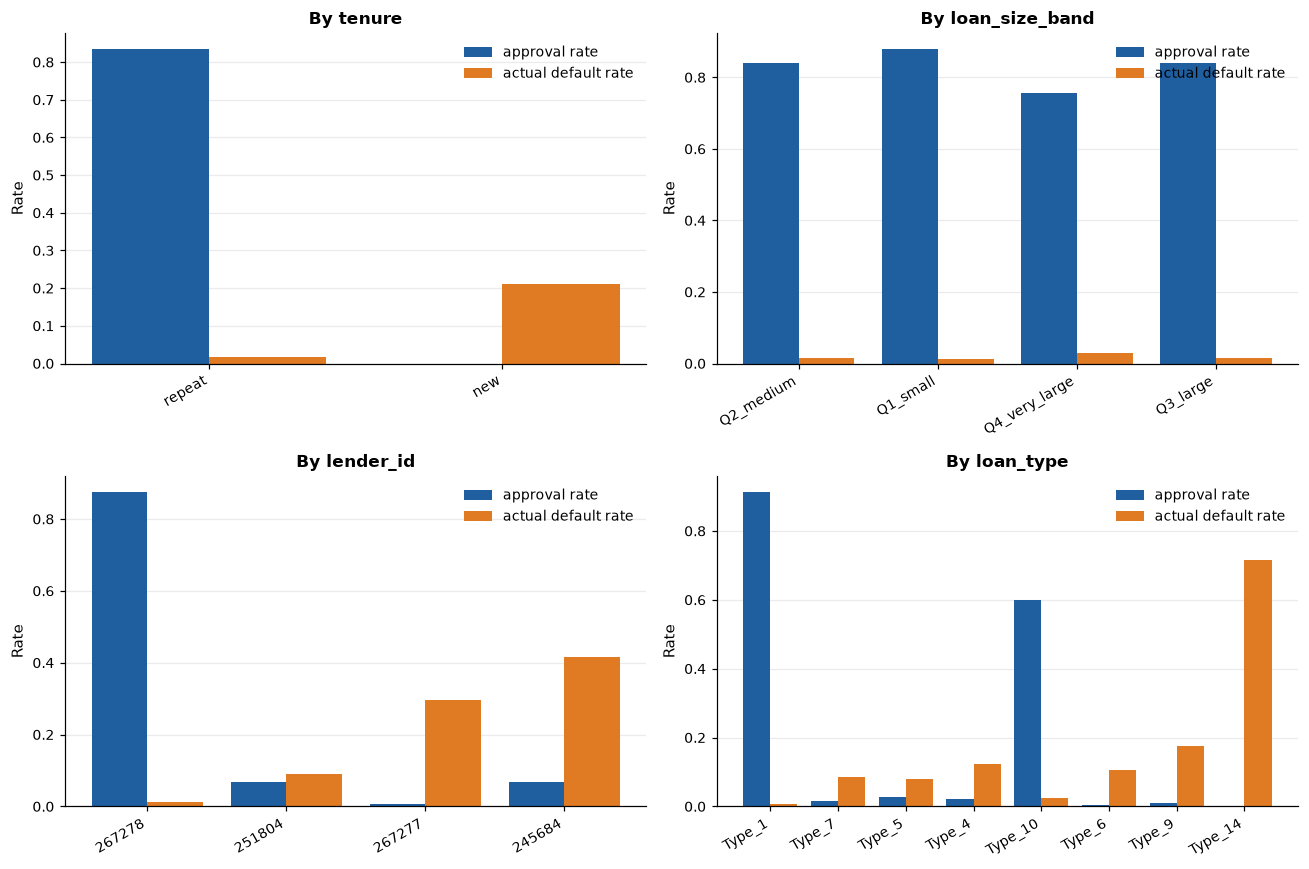

In [8]:
fair = oof["logreg"].assign(y_pred=oof["logreg"]["y_cal"]).merge(train[["ID", "log_amount_usd"]], on="ID")
fair["loan_size_band"] = add_loan_size_band(fair)
fair["tenure"] = np.where(fair["is_new_borrower"] == 1, "new", "repeat")

cols = ["group", "n", "selection_rate", "actual_default_rate", "mean_pred_prob", "pr_auc", "f1", "fpr", "disparate_impact_ratio"]
tables = {c: disaggregated_evaluation(fair, c, threshold=THR) for c in ["tenure", "loan_size_band", "lender_id", "loan_type"]}
for c, t in tables.items():
    print(f"--- {c}")
    display(t[cols].head(8).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (c, t) in zip(axes.ravel(), tables.items()):
    plot_group_selection_rates(t.head(8), ax=ax)
plt.tight_layout()
plt.show()

In [9]:
# Country: Test predictions from the scorer (unlabelled, so selection rate and mean score only)
disaggregated_evaluation(sc.rename(columns={"probability_of_default": "y_pred"}), "country_id", threshold=THR)[
    ["group", "n", "selection_rate", "mean_pred_prob", "disparate_impact_ratio"]].round(3)

,group,n,selection_rate,mean_pred_prob,disparate_impact_ratio
0,Kenya,15069,0.830,0.017,1.000
1,Ghana,3525,0.701,0.081,0.845


**Reading.**
- **First-time borrowers are never approved.** Their approval rate is **0%** against 83.5% for repeat borrowers, a disparate-impact ratio of 0. Their mean calibrated risk is 0.185 against a threshold of 0.019, so every one of them falls above it. The gap follows real risk (they default 21% of the time, against 1.7%), but it is total. Under this cost matrix NkwaPay would never gain a new customer, and the people with no history are the ones Findex shows are excluded already (§4).
- **Loan size: the tool is mildly regressive the other way.** The smallest loans are approved most (88%) and the largest least (75.5%, ratio 0.86). That follows their default rates (1.3% against 2.9%) and stays above 0.8.
- **Lender and product: big gaps, mostly real.** Lender 267278 (94% of rows, 1.2% default) is approved 88% of the time, while the three small lenders are approved under 7% (9–42% default). Type_1 is approved 91%, and Type_7, 5, 4, 6, 9 and 14 are approved under 3%. Here the cost threshold does what it is designed to do. The fairness concern is that a borrower does not choose their lender or product the way they choose an amount, which is why the decline message should not lead with lender (see `docs/audit/decline_explanation.md`).
- **Country:** on Test, Kenyan applications pass the risk threshold 83% of the time and Ghanaian ones 70% of the time. After the limit rule (§2.3), however, no Ghanaian is approved for the amount requested.

### 3.2 Sensitivity to the cost matrix

The threshold is a business choice, so the fairness picture has to be read against it. Henry's cedi threshold (0.036, D-22) is the main alternative.

In [10]:
pd.concat({
    f"shipped {THR:.3f}": disaggregated_evaluation(fair, "tenure", threshold=THR).set_index("group")[["selection_rate", "disparate_impact_ratio"]],
    f"cedi {THR_GHS}": disaggregated_evaluation(fair, "tenure", threshold=THR_GHS).set_index("group")[["selection_rate", "disparate_impact_ratio"]],
    "6 future loans lost": disaggregated_evaluation(fair, "tenure", threshold=cost_matrix_threshold(future_loans=6)["threshold"]).set_index("group")[["selection_rate", "disparate_impact_ratio"]],
}, axis=1).round(3)

shipped 0.019                            cedi 0.036                        6 future loans lost                       
       selection_rate disparate_impact_ratio selection_rate disparate_impact_ratio      selection_rate disparate_impact_ratio
group                                                                                                                        
repeat          0.835                    1.0          0.917                  1.000               0.981                  1.000
new             0.000                    0.0          0.120                  0.131               0.489                  0.498

**Reading.** At the cedi threshold, 12% of first-time borrowers are approved (ratio 0.13). If declining a good borrower costs the 6 loans a typical customer takes (the config's sensitivity value), the threshold rises to 0.106 and first-time approval rises to 49% (repeat borrowers rise to 98%, so the ratio is 0.50). **The exclusion is driven more by the cost assumptions than by the model.** Whether a lost customer costs 1 future loan or 6 is the single most important number for fairness here, and it is still an assumption.

### 3.3 Proxy analysis: which inputs stand in for country or tenure? (fixes draft problem 3)

We have no gender, age or region in the loan data, so the protected-attribute question has to be asked indirectly. Do any model inputs *identify* a group we might treat unfairly? Proxy strength = |AUC − 0.5| × 2 of each feature on its own: 0 means no information about the group, 1 means it identifies the group perfectly.

In [11]:
feats = C.NUM_FEATURES_T2 + C.CAT_FEATURES
gh_proxy = proxy_strength(df.assign(is_ghana=df["country_id"].eq("Ghana").astype(int)), "is_ghana", feats)
new_proxy = proxy_strength(train, "is_new_borrower", [f for f in feats if f != "is_new_borrower"])
pd.concat({"proxy for Ghana": gh_proxy.head(6).reset_index(drop=True),
           "proxy for first-time borrower": new_proxy.head(6).reset_index(drop=True)}, axis=1).round(3)

proxy for Ghana                       proxy for first-time borrower                      
                feature    auc proxy_strength                       feature    auc proxy_strength
0             lender_id  1.000          1.000                  n_past_loans  0.043          0.914
1             loan_type  1.000          1.000               n_past_labelled  0.084          0.832
2        log_amount_usd  0.948          0.896                     loan_type  0.731          0.463
3       n_past_labelled  0.087          0.825                     lender_id  0.654          0.308
4     n_lenders_on_loan  0.867          0.735                    disb_month  0.381          0.239
5  days_since_last_loan  0.785          0.570                      duration  0.619          0.238

**Reading.**
- **For country:** lender and loan type identify Ghana perfectly (1.0), and the USD amount nearly so (0.90). Even if `country_id` were removed, the model would know which country an application comes from. Fairness across countries therefore has to be tested on outcomes, not assumed from the inputs.
- **For tenure:** `n_past_loans` (0.91) and `n_past_labelled` (0.83) are near-proxies for being new, as expected, and loan type is a moderate one (0.46). Dropping `is_new_borrower` would not remove the tenure gap, because the history fields carry the same information.

So "drop the proxy" is not a viable mitigation here. That leads to a decision-level fix.

### 3.4 Mitigation with its cost (#50; fixes draft problem 2)

**Option tested: a starter-loan threshold for first-time borrowers.** Repeat borrowers keep the shipped rule. First-time borrowers with calibrated risk at or below a separate cut-off `t_new` are offered a loan at a fraction `size` of the request. Costs use the shipped cost matrix:
- an approved defaulter loses `size × principal × (1 − recovery) + collection cost`;
- a declined good borrower loses the full fee;
- a good borrower given a starter loan loses the fee on the part that was not lent.

In [12]:
nb = fair[fair["is_new_borrower"] == 1]
REPEAT_APPROVAL = float(np.mean(fair.loc[fair["is_new_borrower"] == 0, "y_pred"] <= THR))

def starter_option(t_new, size, cm):
    approve = nb["y_pred"] <= t_new
    y = nb["y_true"].astype(int)
    c_fn = size * cm["principal"] * (1 - cm["recovery_rate"]) + cm["collection_cost"]
    cost = ((approve & (y == 1)).sum() * c_fn + (~approve & (y == 0)).sum() * cm["c_fp"]
            + (approve & (y == 0)).sum() * (1 - size) * cm["c_fp"])
    return {"t_new": t_new, "size": size, "approval_new": approve.mean(), "ratio_vs_repeat": approve.mean() / REPEAT_APPROVAL,
            "approved": int(approve.sum()), "defaulters_approved": int((approve & (y == 1)).sum()), "total_cost_KES": cost}

options = [(THR, 1.0)] + [(t, s) for t in (0.036, 0.05, 0.10, 0.20) for s in (1.0, 0.5, 0.25)]
mit = pd.DataFrame([starter_option(t, s, cost) for t, s in options])
mit["extra_cost_KES"] = mit["total_cost_KES"] - mit["total_cost_KES"].iloc[0]
mit["extra_per_new_applicant"] = mit["extra_cost_KES"] / len(nb)
mit.round(3)

,t_new,size,approval_new,ratio_vs_repeat,approved,defaulters_approved,total_cost_KES,extra_cost_KES,extra_per_new_applicant
0,0.019,1.00,0.000,0.000,0,0,39506.074,0.000,0.000
1,0.036,1.00,0.120,0.144,68,3,47121.766,7615.692,13.432
2,0.036,0.50,0.120,0.144,68,3,43688.920,4182.846,7.377
3,0.036,0.25,0.120,0.144,68,3,41972.497,2466.423,4.350
4,0.050,1.00,0.360,0.431,204,10,66890.533,27384.459,48.297
5,0.050,0.50,0.360,0.431,204,10,54448.303,14942.230,26.353
6,0.050,0.25,0.360,0.431,204,10,48227.188,8721.115,15.381
7,0.100,1.00,0.487,0.583,276,16,87765.642,48259.568,85.114
8,0.100,0.50,0.487,0.583,276,16,65635.858,26129.784,46.084
9,0.100,0.25,0.487,0.583,276,16,54570.966,15064.892,26.569


In [13]:
# Before / after for the recommended option: first-time borrowers with p <= 0.05 get a 25% starter loan
T_NEW, SIZE = 0.05, 0.25
fair["approve_before"] = fair["y_pred"] <= THR
fair["approve_after"] = np.where(fair["is_new_borrower"] == 1, fair["y_pred"] <= T_NEW, fair["approve_before"])
rows = []
for label, col in [("before", "approve_before"), ("after", "approve_after")]:
    money = decision_cost_by_group(fair, "tenure", col, c_fp=cost["c_fp"], c_fn=cost["c_fn"]).set_index("group")
    for g, gdf in fair.groupby("tenure"):
        thr_g = T_NEW if (label == "after" and g == "new") else THR
        m = classification_metrics(gdf["y_true"], gdf["y_pred"], threshold=thr_g)
        rows.append({"when": label, "group": g, "approval": gdf[col].mean(), "pr_auc": m["pr_auc"], "f1": m["f1"],
                     "defaults_approved": money.loc[g, "defaults_approved"],
                     "cost_per_applicant_full_size_KES": money.loc[g, "cost_per_applicant"]})
ba = pd.DataFrame(rows)
new_after = ba.query("when == 'after' and group == 'new'").index
ba.loc[new_after, "cost_per_applicant_starter_KES"] = mit.query("t_new == @T_NEW and size == @SIZE")["total_cost_KES"].iloc[0] / len(nb)
ba.round(3)

,when,group,approval,pr_auc,f1,defaults_approved,cost_per_applicant_full_size_KES,cost_per_applicant_starter_KES
0,before,new,0.000,0.569,0.347,0,69.676,NaN
1,before,repeat,0.835,0.127,0.118,412,40.515,NaN
2,after,new,0.360,0.569,0.452,10,117.973,85.057
3,after,repeat,0.835,0.127,0.118,412,40.515,NaN


**Reading and recommendation.**
- **Doing nothing** costs KES 39.5k on these 567 first-time borrowers, all of it fees lost by declining 448 people who would have repaid.
- **A full-size loan for anyone at p ≤ 0.05** approves 36% of first-time borrowers for an extra KES 27k. Cutting the starter loan to **25% of the request** gives the same 36% approval for an extra **KES 8.7k**, about **KES 15 per first-time applicant**, or KES 43 per extra person approved. That works because a defaulted starter loan loses a quarter of the principal.
- **What it does not fix:** the ratio is still 0.43, well below 0.8. Reaching 0.8 needs `t_new` ≈ 0.20, where 11% of the people approved default, at an extra KES 50k even with a 25% starter size.
- **Recommendation: ship the 25% starter loan at p ≤ 0.05** (36% approval, about 4.9% of those approved default). Repaying it builds the history the model needs. Report the ratio honestly as 0.43, and ask the team to settle the future-loans assumption: at 6 lost loans (§3.2), the shipped rule itself approves 49% of first-time borrowers.
- PR-AUC is the same before and after, because a group threshold changes decisions, not the ranking. F1 for first-time borrowers is shown at their own threshold.

## 4. Who in Ghana cannot access credit today? (#28)

World Bank Global Findex 2021, Ghana, survey-weighted (`wgt`). This describes the **adult population**, not our applicants.

In [14]:
findex_access(pd.read_csv(C.FINDEX_CSV)).round(1)

,group,n,has_account,mobile_money,borrowed_formally,borrowed_any
0,All adults,1000,68.2,59.7,7.2,52.2
1,Women,465,62.6,55.0,5.6,47.9
2,Men,535,74.2,64.6,9.0,56.7
3,Rural,360,56.5,47.9,6.6,52.0
4,Urban,640,76.1,67.6,7.7,52.4
5,Poorest 40%,309,54.7,46.4,4.9,52.1
6,Richest 60%,691,77.2,68.5,8.8,52.3
7,Primary or less,295,51.6,42.9,4.7,50.3
8,Tertiary,64,98.3,90.7,32.0,62.0


**Reading.** Only 7.2% of Ghanaian adults borrowed from a formal institution. The rate is lower for women (5.6% against 9.0% for men), for rural adults (6.6% against 7.7% urban), for the poorest 40% (4.9% against 8.8%) and for adults with primary education or less (4.7%). It reaches 32% for the tertiary-educated.

About 40% of adults have no mobile-money account at all, so they cannot even reach a digital lender. **Does our model narrow or widen the gap?** As shipped, it widens it. It declines every first-time borrower (§3.1), and first-time borrowers are, by Findex, disproportionately the women, rural and poorer adults who have never had formal credit. It also learned only from people lenders already approved (D-14), so it has never seen the excluded. The starter loan (§3.4) is the smallest change that gives them a way in.

## 5. Summary for the report

| Question | Answer | Evidence |
| --- | --- | --- |
| Best ranking model | Random Forest (PR-AUC 0.203 by customer), but the ensembles' edge vanishes by time (ROC-AUC ≈ 0.6 for all) | §1 |
| Shipped model | Logistic regression, Platt-calibrated; it approves 83% of Kenyan applicants at p\* 0.019 | §1.1 |
| Is Ghana like Kenya? | No. Domain AUC 0.985 even without the label-history artefact; importance weighting is unusable (ESS share 0.04) | §2.2 |
| What happens to Ghana | No full approvals: 70% are limited to about 16% of the request and 30% are declined; the result swings to 79% declined under a different history assumption | §2.3 |
| Trust in Ghana needs | A capped pilot of ~3,500 loans over ~3 months, history encoded as unknown, Ghana recalibration, monitoring triggers | §2.4 |
| Biggest fairness gap | First-time borrowers: 0% approved (ratio 0), real default rate 21% | §3.1 |
| Proxies | Lender and product identify Ghana perfectly; the history fields identify first-time borrowers | §3.3 |
| Mitigation | A 25% starter loan at p ≤ 0.05: 0% → 36% approved for about KES 15 per first-time applicant; the ratio stays at 0.43 | §3.4 |
| Access | Formal borrowing is 7.2%, lower for women, rural, poor and less-educated adults; as shipped, the model widens the gap | §4 |